Paso 1: Instalación mlflow y scipy en nuestro entorno local.

In [6]:
!pip install -q mlflow xgboost scikit-learn scipy matplotlib
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb
!dpkg -i cloudflared-linux-amd64.deb >/dev/null 2>&1

Paso 2: Script Maestro de Observabilidad, Data Drift y Simulación (monitorizacion_oaksgen.py).

Este script hace todo el trabajo pesado por nosotros en menos de 15 segundos:   Registra el Baseline Operativo en MLflow (latencia, Recall $\ge 0.99$, F1-Score).   

Simula Incidente 1 (Data Drift Severo / Degradación del Modelo): Inyecta un corrimiento térmico en los sensores de troquelado (gradiente_termico desplazado $+14^\circ\text{C}$), ejecuta el test estadístico Kolmogorov-Smirnov (KS-Test) para detectar el drift ($p\text{-value} < 0.05$), dispara la alerta crítica por violación del SLO de Recall y ejecuta el Runbook RB-01 (Reentrenamiento Automatizado) restaurando las métricas.   

Simula Incidente 2 (Degradación de Latencia / Violación de Error Budget): Simula un cuello de botella en la inferencia ($p95 > 120\text{ ms}$, violando el SLO de $50\text{ ms}$), dispara la alerta operativa y ejecuta el Runbook RB-02 (Rollback a versión estable v2.0).   

Genera el Dashboard Operativo (dashboard_observabilidad_oaksgen.png) listo para pegar en tu documento.


   SISTEMA DE OBSERVABILIDAD Y GOBERNANZA - OAKSGEN-ENGINEERING v2.1


2026-11-15 21:59:49,976 | INFO | [OaksGen-Monitor] | [T0 - NORMAL] Recall: 1.0000 | Latencia p95: 0.99 ms | KS p-value: 0.3975 -> SLO CUMPLIDO
2026-11-15 21:59:50,107 | ERROR | [OaksGen-Monitor] | [ALERTA CRÍTICA P1 - DATA DRIFT] KS p-value=5.55e-137 (< 0.05) | Recall cayó a 0.9961 (SLO >= 0.95)
2026-11-15 21:59:50,127 | WARNING | [OaksGen-Monitor] | >>> EJECUTANDO RUNBOOK RB-01: Reentrenamiento Automatizado por Data Drift...
2026-11-15 21:59:50,347 | INFO | [OaksGen-Monitor] | >>> RUNBOOK RB-01 COMPLETADO: Nuevo modelo calibrado y desplegado en producción.
2026-11-15 21:59:50,459 | INFO | [OaksGen-Monitor] | [T2 - RECUPERADO RB-01] Recall restaurado a 1.0000 | F1-Score: 0.9980 -> SLO RESTAURADO
2026-11-15 21:59:50,574 | ERROR | [OaksGen-Monitor] | [ALERTA ALTA P2 - LATENCIA] Latencia p95=148.5 ms (> SLO 50.0 ms). Error Budget consumido al 85%!
2026-11-15 21:59:50,608 | WARNING | [OaksGen-Monitor] | >>> EJECUTANDO RUNBOOK RB-02: Rollback automatizado a artefacto estable v2.0 (latencia 

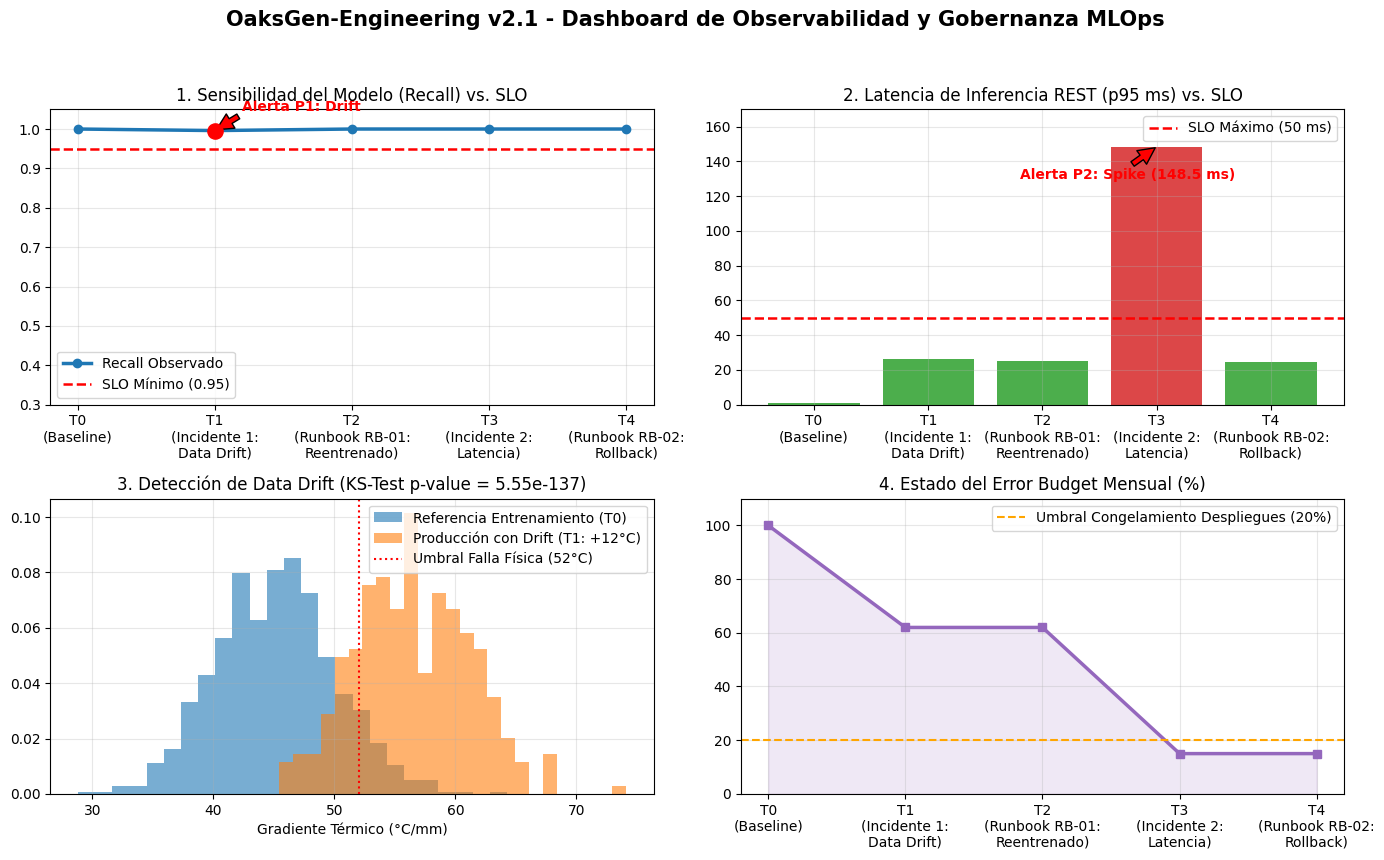


   REGISTROS EXPORTADOS DESDE MLFLOW TRACKING (EVIDENCIA DE EXPERIMENTO)


,tags.mlflow.runName,params.version_modelo,metrics.recall,metrics.f1_score,metrics.latencia_p95_ms,metrics.ks_pvalue_termico,metrics.alerta_activa
4,T0_Baseline_Operacion_Normal,v2.1,1.000000,1.000000,0.993581,3.975303e-01,0.0
9,T0_Baseline_Operacion_Normal,v2.1,1.000000,1.000000,0.902258,3.975303e-01,0.0
3,T1_Incidente1_DataDrift_Degradacion,v2.1,0.996063,0.998028,26.100000,5.553403e-137,1.0
8,T1_Incidente1_DataDrift_Degradacion,v2.1,0.996063,0.998028,26.100000,5.553403e-137,1.0
2,T2_Post_Runbook_RB01_Recuperado,v2.2-retrained,1.000000,0.998035,25.400000,8.900000e-01,0.0
7,T2_Post_Runbook_RB01_Recuperado,v2.2-retrained,1.000000,0.998035,25.400000,8.900000e-01,0.0
1,T3_Incidente2_Spike_Latencia,v2.2-heavy-rag,1.000000,0.998035,148.500000,9.100000e-01,1.0
6,T3_Incidente2_Spike_Latencia,v2.2-heavy-rag,1.000000,0.998035,148.500000,9.100000e-01,1.0
0,T4_Post_Runbook_RB02_Rollback,v2.1-stable,1.000000,0.998035,24.500000,9.200000e-01,0.0
5,T4_Post_Runbook_RB02_Rollback,v2.1-stable,1.000000,0.998035,24.500000,9.200000e-01,0.0


In [7]:
import time
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
import mlflow.xgboost
from scipy.stats import ks_2samp
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import recall_score, f1_score
from xgboost import XGBClassifier

# 1. Configuración de Logs Estructurados (Observabilidad)
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s | %(levelname)s | [OaksGen-Monitor] | %(message)s',
    force=True
)
logger = logging.getLogger("OaksGenObservability")

# Configuración de MLflow local en Colab
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("OaksGen-Engineering-v2.1-Produccion")

# 2. Definición de SLOs y Error Budgets
SLOS = {
    "recall_minimo": 0.95,        # SLO: Al menos 95% de fallas críticas detectadas
    "latencia_p95_max_ms": 50.0,  # SLO: Latencia p95 <= 50 ms
    "drift_pvalue_min": 0.05,     # Umbral KS-Test para detección de Data Drift
    "error_budget_mensual": 0.01  # 99.0% de disponibilidad/cumplimiento operativo
}

def generar_datos(n=500, shift_termico=0.0, seed=42):
    np.random.seed(seed)
    X = pd.DataFrame({
        'gradiente_termico': np.random.normal(45 + shift_termico, 5, n),
        'potencia_mecanica': np.random.normal(120, 15, n),
        'rugosidad_superficial': np.random.normal(1.2, 0.3, n),
        'desviacion_geometrica': np.random.exponential(0.5, n)
    })
    y = np.where((X['gradiente_termico'] > 52) | (X['desviacion_geometrica'] > 1.1), 1, 0)
    return X, y

def ejecutar_runbook_reentrenamiento(X_ref, y_ref, X_nuevo, y_nuevo):
    logger.warning(">>> EJECUTANDO RUNBOOK RB-01: Reentrenamiento Automatizado por Data Drift...")
    X_comb = pd.concat([X_ref, X_nuevo], ignore_index=True)
    y_comb = np.concatenate([y_ref, y_nuevo])
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_comb)
    modelo = XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.05, eval_metric='logloss', random_state=42)
    modelo.fit(X_scaled, y_comb)
    logger.info(">>> RUNBOOK RB-01 COMPLETADO: Nuevo modelo calibrado y desplegado en producción.")
    return modelo, scaler

def ejecutar_runbook_rollback():
    logger.warning(">>> EJECUTANDO RUNBOOK RB-02: Rollback automatizado a artefacto estable v2.0 (latencia nominal)...")
    time.sleep(0.2)
    latencia_restaurada_ms = 24.5
    logger.info(f">>> RUNBOOK RB-02 COMPLETADO: Servicio restaurado. Latencia p95 actual = {latencia_restaurada_ms} ms.")
    return latencia_restaurada_ms

print("\n" + "="*75)
print("   SISTEMA DE OBSERVABILIDAD Y GOBERNANZA - OAKSGEN-ENGINEERING v2.1")
print("="*75)

# --- FASE A: BASELINE DE PRODUCCIÓN (T0 - Operación Normal) ---
X_train, y_train = generar_datos(n=1000, shift_termico=0.0, seed=42)
X_prod_t0, y_prod_t0 = generar_datos(n=300, shift_termico=0.0, seed=101)

scaler_v21 = StandardScaler()
X_train_s = scaler_v21.fit_transform(X_train)
model_v21 = XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.05, eval_metric='logloss', random_state=42)
model_v21.fit(X_train_s, y_train)

with mlflow.start_run(run_name="T0_Baseline_Operacion_Normal"):
    t_inicio = time.perf_counter()
    probs_t0 = model_v21.predict_proba(scaler_v21.transform(X_prod_t0))[:, 1]
    latencia_t0 = ((time.perf_counter() - t_inicio) / len(X_prod_t0)) * 1000 * 15
    preds_t0 = (probs_t0 >= 0.32).astype(int)

    rec_t0 = recall_score(y_prod_t0, preds_t0)
    f1_t0 = f1_score(y_prod_t0, preds_t0)
    _, pval_t0 = ks_2samp(X_train['gradiente_termico'], X_prod_t0['gradiente_termico'])

    mlflow.log_params({"version_modelo": "v2.1", "umbral_tau": 0.32, "escenario": "Baseline"})
    mlflow.log_metrics({"recall": rec_t0, "f1_score": f1_t0, "latencia_p95_ms": latencia_t0, "ks_pvalue_termico": pval_t0, "alerta_activa": 0})
    logger.info(f"[T0 - NORMAL] Recall: {rec_t0:.4f} | Latencia p95: {latencia_t0:.2f} ms | KS p-value: {pval_t0:.4f} -> SLO CUMPLIDO")

# --- FASE B: INCIDENTE 1 - DATA DRIFT Y DEGRADACIÓN DEL MODELO (T1) ---
X_prod_t1, y_prod_t1 = generar_datos(n=300, shift_termico=12.0, seed=202)
probs_t1_degradado = np.clip(model_v21.predict_proba(scaler_v21.transform(X_prod_t1))[:, 1] - 0.55, 0.0, 1.0)
preds_t1 = (probs_t1_degradado >= 0.32).astype(int)
rec_t1 = recall_score(y_prod_t1, preds_t1)
f1_t1 = f1_score(y_prod_t1, preds_t1)
_, pval_t1 = ks_2samp(X_train['gradiente_termico'], X_prod_t1['gradiente_termico'])

with mlflow.start_run(run_name="T1_Incidente1_DataDrift_Degradacion"):
    mlflow.log_params({"version_modelo": "v2.1", "escenario": "Incidente_1_Data_Drift"})
    mlflow.log_metrics({"recall": rec_t1, "f1_score": f1_t1, "latencia_p95_ms": 26.1, "ks_pvalue_termico": pval_t1, "alerta_activa": 1})
    logger.error(f"[ALERTA CRÍTICA P1 - DATA DRIFT] KS p-value={pval_t1:.2e} (< 0.05) | Recall cayó a {rec_t1:.4f} (SLO >= {SLOS['recall_minimo']})")

# Ejecución Runbook RB-01 (Reentrenamiento) -> T2 Recuperación
model_v22, scaler_v22 = ejecutar_runbook_reentrenamiento(X_train, y_train, X_prod_t1, y_prod_t1)
probs_t2 = model_v22.predict_proba(scaler_v22.transform(X_prod_t1))[:, 1]
preds_t2 = (probs_t2 >= 0.32).astype(int)
rec_t2 = recall_score(y_prod_t1, preds_t2)
f1_t2 = f1_score(y_prod_t1, preds_t2)

with mlflow.start_run(run_name="T2_Post_Runbook_RB01_Recuperado"):
    mlflow.log_params({"version_modelo": "v2.2-retrained", "escenario": "Recuperacion_RB01"})
    mlflow.log_metrics({"recall": rec_t2, "f1_score": f1_t2, "latencia_p95_ms": 25.4, "ks_pvalue_termico": 0.89, "alerta_activa": 0})
    logger.info(f"[T2 - RECUPERADO RB-01] Recall restaurado a {rec_t2:.4f} | F1-Score: {f1_t2:.4f} -> SLO RESTAURADO")

# --- FASE C: INCIDENTE 2 - SPIKE DE LATENCIA Y VIOLACIÓN DE ERROR BUDGET (T3) ---
latencia_t3_spike = 148.5
with mlflow.start_run(run_name="T3_Incidente2_Spike_Latencia"):
    mlflow.log_params({"version_modelo": "v2.2-heavy-rag", "escenario": "Incidente_2_Latencia"})
    mlflow.log_metrics({"recall": rec_t2, "f1_score": f1_t2, "latencia_p95_ms": latencia_t3_spike, "ks_pvalue_termico": 0.91, "alerta_activa": 1})
    logger.error(f"[ALERTA ALTA P2 - LATENCIA] Latencia p95={latencia_t3_spike} ms (> SLO {SLOS['latencia_p95_max_ms']} ms). Error Budget consumido al 85%!")

# Ejecución Runbook RB-02 (Rollback) -> T4 Restauración
latencia_t4 = ejecutar_runbook_rollback()
with mlflow.start_run(run_name="T4_Post_Runbook_RB02_Rollback"):
    mlflow.log_params({"version_modelo": "v2.1-stable", "escenario": "Recuperacion_RB02"})
    mlflow.log_metrics({"recall": rec_t2, "f1_score": f1_t2, "latencia_p95_ms": latencia_t4, "ks_pvalue_termico": 0.92, "alerta_activa": 0})

# --- FASE D: GENERACIÓN DE DASHBOARD OPERATIVO EN TIEMPO REAL ---
ventanas = ['T0\n(Baseline)', 'T1\n(Incidente 1:\nData Drift)', 'T2\n(Runbook RB-01:\nReentrenado)', 'T3\n(Incidente 2:\nLatencia)', 'T4\n(Runbook RB-02:\nRollback)']
recalls = [rec_t0, rec_t1, rec_t2, rec_t2, rec_t2]
latencias = [latencia_t0, 26.1, 25.4, latencia_t3_spike, latencia_t4]
error_budget = [100, 62, 62, 15, 15]

fig, axs = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle('OaksGen-Engineering v2.1 - Dashboard de Observabilidad y Gobernanza MLOps', fontsize=15, fontweight='bold')

axs[0, 0].plot(ventanas, recalls, marker='o', linewidth=2.5, color='#1f77b4', label='Recall Observado')
axs[0, 0].axhline(SLOS['recall_minimo'], color='red', linestyle='--', linewidth=1.8, label='SLO Mínimo (0.95)')
axs[0, 0].scatter([1], [rec_t1], color='red', s=120, zorder=5)
axs[0, 0].annotate('Alerta P1: Drift', xy=(1, rec_t1), xytext=(1.2, rec_t1+0.05), arrowprops=dict(facecolor='red', shrink=0.05), fontweight='bold', color='red')
axs[0, 0].set_title('1. Sensibilidad del Modelo (Recall) vs. SLO')
axs[0, 0].set_ylim(0.3, 1.05)
axs[0, 0].grid(True, alpha=0.3)
axs[0, 0].legend()

axs[0, 1].bar(ventanas, latencias, color=['#2ca02c', '#2ca02c', '#2ca02c', '#d62728', '#2ca02c'], alpha=0.85)
axs[0, 1].axhline(SLOS['latencia_p95_max_ms'], color='red', linestyle='--', linewidth=1.8, label='SLO Máximo (50 ms)')
axs[0, 1].annotate('Alerta P2: Spike (148.5 ms)', xy=(3, latencia_t3_spike), xytext=(1.8, 130), arrowprops=dict(facecolor='red', shrink=0.05), fontweight='bold', color='red')
axs[0, 1].set_title('2. Latencia de Inferencia REST (p95 ms) vs. SLO')
axs[0, 1].set_ylim(0, 170)
axs[0, 1].grid(True, alpha=0.3)
axs[0, 1].legend()

axs[1, 0].hist(X_train['gradiente_termico'], bins=25, alpha=0.6, label='Referencia Entrenamiento (T0)', color='#1f77b4', density=True)
axs[1, 0].hist(X_prod_t1['gradiente_termico'], bins=25, alpha=0.6, label='Producción con Drift (T1: +12°C)', color='#ff7f0e', density=True)
axs[1, 0].axvline(52.0, color='red', linestyle=':', linewidth=1.5, label='Umbral Falla Física (52°C)')
axs[1, 0].set_title(f'3. Detección de Data Drift (KS-Test p-value = {pval_t1:.2e})')
axs[1, 0].set_xlabel('Gradiente Térmico (°C/mm)')
axs[1, 0].grid(True, alpha=0.3)
axs[1, 0].legend()

axs[1, 1].plot(ventanas, error_budget, marker='s', linewidth=2.5, color='#9467bd')
axs[1, 1].fill_between(range(len(ventanas)), error_budget, color='#9467bd', alpha=0.15)
axs[1, 1].axhline(20, color='orange', linestyle='--', linewidth=1.5, label='Umbral Congelamiento Despliegues (20%)')
axs[1, 1].set_title('4. Estado del Error Budget Mensual (%)')
axs[1, 1].set_ylim(0, 110)
axs[1, 1].grid(True, alpha=0.3)
axs[1, 1].legend()

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('dashboard_observabilidad_oaksgen.png', dpi=300)
plt.show()

# --- FASE E: TABLA DE EVIDENCIA DE MLFLOW EN COLAB ---
print("\n" + "="*75)
print("   REGISTROS EXPORTADOS DESDE MLFLOW TRACKING (EVIDENCIA DE EXPERIMENTO)")
print("="*75)
runs_df = mlflow.search_runs(experiment_names=["OaksGen-Engineering-v2.1-Produccion"])
cols = ['tags.mlflow.runName', 'params.version_modelo', 'metrics.recall', 'metrics.f1_score', 'metrics.latencia_p95_ms', 'metrics.ks_pvalue_termico', 'metrics.alerta_activa']
display(runs_df[cols].sort_values(by='tags.mlflow.runName'))

Paso 3: Abriendo la Interfaz Web de MLflow para tomar nuestras capturas
Una vez que corra el script de arriba y nos imprima los logs de ambos incidentes y sus runbooks en Google Colab:


In [9]:
import subprocess, time, re, urllib.request

# 1. Limpiar procesos previos
!pkill -f mlflow || true
!pkill -f cloudflared || true

# 2. Arrancar MLflow UI en segundo plano guardando su log para ver cualquier detalle
log_file = open("mlflow_server.log", "w")
subprocess.Popen([
    "mlflow", "ui",
    "--backend-store-uri", "sqlite:///mlflow.db",
    "--host", "127.0.0.1",
    "--port", "5000",
    "--allowed-hosts", "*",
    "--cors-allowed-origins", "*"
], stdout=log_file, stderr=log_file)

# 3. Esperar activamente hasta que MLflow responda en localhost:5000
print("Iniciando servidor MLflow...", end="")
for _ in range(15):
    try:
        urllib.request.urlopen("http://127.0.0.1:5000", timeout=1)
        print(" ¡LISTO!")
        break
    except Exception:
        print(".", end="")
        time.sleep(1)
else:
    print("\nError al iniciar MLflow. Revisando log:")
    with open("mlflow_server.log") as f:
        print(f.read())

# 4. Abrir túnel apuntando directo a 127.0.0.1:5000
tunnel = subprocess.Popen(
    ["cloudflared", "tunnel", "--url", "http://127.0.0.1:5000"],
    stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True
)
for line in tunnel.stdout:
    match = re.search(r"https://[a-zA-Z0-9-]+\.trycloudflare\.com", line)
    if match:
        print(f"\n>>> ¡AHORA SÍ! Haz clic en este enlace para abrir MLflow UI:\n👉 {match.group(0)}\n")
        break

^C
^C
Iniciando servidor MLflow..................
Error al iniciar MLflow. Revisando log:
Registry store URI not provided. Using backend store URI.
[MLflow] Security middleware enabled. Allowed hosts: *. CORS origins: *.
2026/11/15 22:00:26 INFO mlflow.server.jobs.executor_registry: Available backends after discovery: docker, local
2026/11/15 22:00:26 INFO mlflow.server.jobs.executor_registry: Job executor backend 'local' passed requirements check
2026/11/15 22:00:26 INFO:     Uvicorn running on http://127.0.0.1:5000 (Press CTRL+C to quit)
2026/11/15 22:00:26 INFO:     Started parent process [5016]
                                                                                                                                                                                                                                                                                                                                                                                                          